In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

In [2]:
df = pd.read_csv('NYCTaxiFares.csv')

In [3]:
df.head()

,pickup_datetime,fare_amount,fare_class,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,2010-04-19 08:17:56 UTC,6.5,0,-73.992365,40.730521,-73.975499,40.744746,1
1,2010-04-17 15:43:53 UTC,6.9,0,-73.990078,40.740558,-73.974232,40.744114,1
2,2010-04-17 11:23:26 UTC,10.1,1,-73.994149,40.751118,-73.960064,40.766235,2
3,2010-04-11 21:25:03 UTC,8.9,0,-73.990485,40.756422,-73.971205,40.748192,1
4,2010-04-17 02:19:01 UTC,19.7,1,-73.990976,40.734202,-73.905956,40.743115,1


In [4]:
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'], format='%Y-%m-%d %H:%M:%S UTC', utc=True)

In [5]:
df['pickup_datetime'] = df['pickup_datetime'].dt.tz_convert('America/New_York')

In [6]:
df['year'] = df['pickup_datetime'].dt.year
df['month'] = df['pickup_datetime'].dt.month
df['weekday'] = df['pickup_datetime'].dt.weekday
df['hour'] = df['pickup_datetime'].dt.hour

In [7]:
df.head()

,pickup_datetime,fare_amount,fare_class,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,year,month,weekday,hour
0,2010-04-19 04:17:56-04:00,6.5,0,-73.992365,40.730521,-73.975499,40.744746,1,2010,4,0,4
1,2010-04-17 11:43:53-04:00,6.9,0,-73.990078,40.740558,-73.974232,40.744114,1,2010,4,5,11
2,2010-04-17 07:23:26-04:00,10.1,1,-73.994149,40.751118,-73.960064,40.766235,2,2010,4,5,7
3,2010-04-11 17:25:03-04:00,8.9,0,-73.990485,40.756422,-73.971205,40.748192,1,2010,4,6,17
4,2010-04-16 22:19:01-04:00,19.7,1,-73.990976,40.734202,-73.905956,40.743115,1,2010,4,4,22


In [8]:
def haversine_distance(lat1,lon1,lat2,lon2):
    p = np.pi / 180

    r= 6378.1

    a = 0.5 - np.cos((lat2-lat1)*p)/2 + np.cos(lat1*p) * np.cos(lat2 * p) * (1 - np.cos((lon2 - lon1) * p))/2
    
    distance = 2 * r * np.arcsin(np.sqrt(a))
    
    return distance



In [9]:
df['distance'] = haversine_distance(df['pickup_latitude'],df['pickup_longitude'],df['dropoff_latitude'],df['dropoff_longitude'])

In [10]:
df.head()

,pickup_datetime,fare_amount,fare_class,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,year,month,weekday,hour,distance
0,2010-04-19 04:17:56-04:00,6.5,0,-73.992365,40.730521,-73.975499,40.744746,1,2010,4,0,4,2.128681
1,2010-04-17 11:43:53-04:00,6.9,0,-73.990078,40.740558,-73.974232,40.744114,1,2010,4,5,11,1.393858
2,2010-04-17 07:23:26-04:00,10.1,1,-73.994149,40.751118,-73.960064,40.766235,2,2010,4,5,7,3.330471
3,2010-04-11 17:25:03-04:00,8.9,0,-73.990485,40.756422,-73.971205,40.748192,1,2010,4,6,17,1.866207
4,2010-04-16 22:19:01-04:00,19.7,1,-73.990976,40.734202,-73.905956,40.743115,1,2010,4,4,22,7.239380


In [11]:
def is_within_radius (lat,lon,cen_lat,cen_lon,radius = 0.8):
    distance = haversine_distance(lat,lon,cen_lat,cen_lon)
    
    return radius <= distance

In [12]:
JFK = (40.641312, -73.778137)
LGA = (40.776928, -73.873962)

df['is_pickup_JFK'] = is_within_radius(df['pickup_latitude'],df['pickup_longitude'],*JFK)
df['is_dropoff_JFK'] = is_within_radius(df['dropoff_latitude'],df['dropoff_longitude'],*JFK)

df['is_pickup_LGA'] = is_within_radius(df['pickup_latitude'],df['pickup_longitude'],*LGA)
df['is_dropoff_LGA'] = is_within_radius(df['dropoff_latitude'],df['dropoff_longitude'],*LGA)


In [13]:
df.head()

,pickup_datetime,fare_amount,fare_class,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,year,month,weekday,hour,distance,is_pickup_JFK,is_dropoff_JFK,is_pickup_LGA,is_dropoff_LGA
0,2010-04-19 04:17:56-04:00,6.5,0,-73.992365,40.730521,-73.975499,40.744746,1,2010,4,0,4,2.128681,True,True,True,True
1,2010-04-17 11:43:53-04:00,6.9,0,-73.990078,40.740558,-73.974232,40.744114,1,2010,4,5,11,1.393858,True,True,True,True
2,2010-04-17 07:23:26-04:00,10.1,1,-73.994149,40.751118,-73.960064,40.766235,2,2010,4,5,7,3.330471,True,True,True,True
3,2010-04-11 17:25:03-04:00,8.9,0,-73.990485,40.756422,-73.971205,40.748192,1,2010,4,6,17,1.866207,True,True,True,True
4,2010-04-16 22:19:01-04:00,19.7,1,-73.990976,40.734202,-73.905956,40.743115,1,2010,4,4,22,7.239380,True,True,True,True


In [14]:
df['lat_vec'] = df['pickup_latitude'] - df['dropoff_latitude']
df['lon_vec'] = df['pickup_longitude'] - df['dropoff_longitude']

In [15]:
df = df[df['fare_amount'] > 0]

In [16]:
df['fare_amount'].max()

np.float64(49.9)

In [17]:
def remove_outliers(data, column, ratio):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - ratio * IQR
    upper_bound = Q3 + ratio * IQR
    
    filtered_data = data[(data[column] >= lower_bound) and (data[column] <= upper_bound)]
    
    return filtered_data

In [18]:
columns_to_drop = ['pickup_datetime', 'fare_class']
df.drop(columns=columns_to_drop,inplace=True)

In [19]:
df.head()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,year,month,weekday,hour,distance,is_pickup_JFK,is_dropoff_JFK,is_pickup_LGA,is_dropoff_LGA,lat_vec,lon_vec
0,6.5,-73.992365,40.730521,-73.975499,40.744746,1,2010,4,0,4,2.128681,True,True,True,True,-0.014225,-0.016866
1,6.9,-73.990078,40.740558,-73.974232,40.744114,1,2010,4,5,11,1.393858,True,True,True,True,-0.003556,-0.015846
2,10.1,-73.994149,40.751118,-73.960064,40.766235,2,2010,4,5,7,3.330471,True,True,True,True,-0.015117,-0.034085
3,8.9,-73.990485,40.756422,-73.971205,40.748192,1,2010,4,6,17,1.866207,True,True,True,True,0.008230,-0.019280
4,19.7,-73.990976,40.734202,-73.905956,40.743115,1,2010,4,4,22,7.239380,True,True,True,True,-0.008913,-0.085020


(array([ 5583., 22771., 23339., 18378., 12893.,  9501.,  6574.,  4399.,
         3277.,  2293.,  1648.,  1134.,   858.,   769.,   857.,   786.,
          771.,   677.,   504.,   404.,   287.,   217.,   157.,   106.,
           79.,    67.,   547.,    35.,    43.,  1046.]),
 array([ 2.5 ,  4.08,  5.66,  7.24,  8.82, 10.4 , 11.98, 13.56, 15.14,
        16.72, 18.3 , 19.88, 21.46, 23.04, 24.62, 26.2 , 27.78, 29.36,
        30.94, 32.52, 34.1 , 35.68, 37.26, 38.84, 40.42, 42.  , 43.58,
        45.16, 46.74, 48.32, 49.9 ]),
 <BarContainer object of 30 artists>)

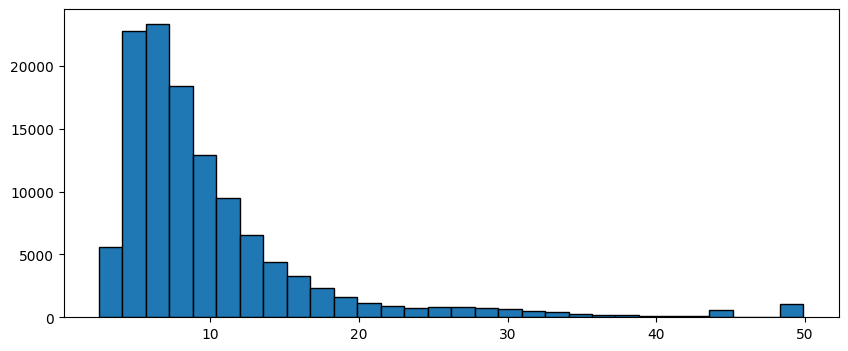

In [20]:
plt.figure(figsize=(10,4))

plt.hist(df['fare_amount'],bins=30,edgecolor='black')